X_train shape:  (60000, 28, 28)
X_test shape:  (10000, 28, 28)
X_train shape:  (60000, 28, 28, 1)
X_test shape:  (10000, 28, 28, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 20ms/step - accuracy: 0.9160 - loss: 0.2651 - val_accuracy: 0.9838 - val_loss: 0.0556
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 17ms/step - accuracy: 0.9707 - loss: 0.0924 - val_accuracy: 0.9882 - val_loss: 0.0439
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9784 - loss: 0.0691 - val_accuracy: 0.9900 - val_loss: 0.0365
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9822 - loss: 0.0574 - val_accuracy: 0.9913 - val_loss: 0.0371
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9843 - loss: 0.0505 - val_accuracy: 0.9918 - val_loss: 0.0319
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9865 - loss: 0.0429 - val_accuracy: 0.9913 - val_loss: 0.0328
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9876 - loss: 0.0388 - val_accuracy: 0.9930 - val_loss: 0.0300
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 15s 18ms/step - accuracy: 0.9886 - loss: 0.0361 - 

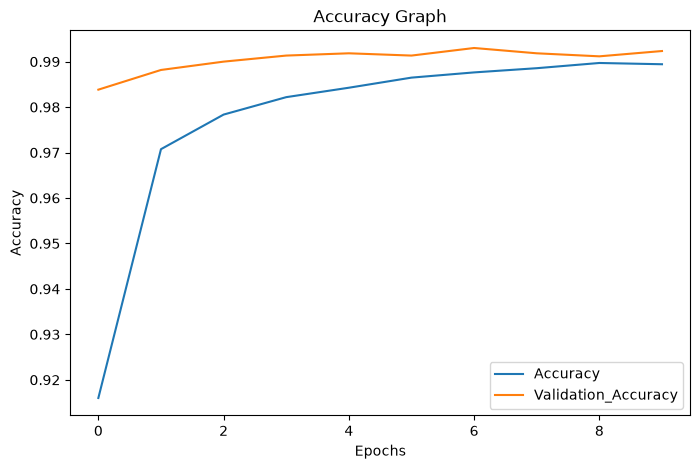

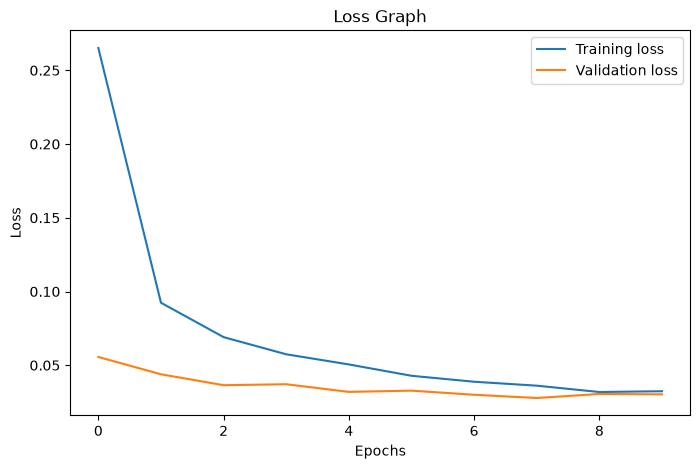

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


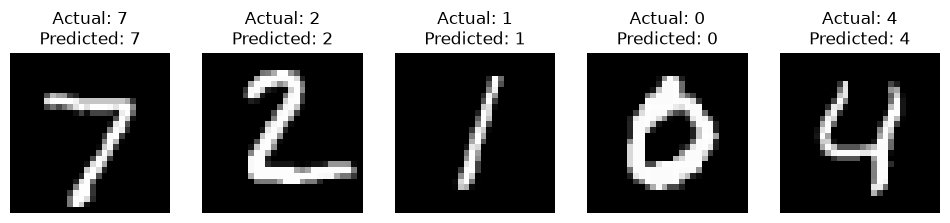

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Input, Dropout

# load dataset
(x_train,y_train),(x_test,y_test) = keras.datasets.mnist.load_data()

print("X_train shape: ",x_train.shape)
print("X_test shape: ",x_test.shape)

# add channel dimension (needed for Conv2D)
x_train = x_train.reshape(-1,28,28,1)
x_test = x_test.reshape(-1,28,28,1)

# normalize
x_train = x_train/255.0
x_test = x_test/255.0

print("X_train shape: ",x_train.shape)
print("X_test shape: ",x_test.shape)

# CNN model (convolution + max pooling)
model = Sequential([
    Input(shape=(28,28,1)),
    Conv2D(32,(3,3),activation="relu"),
    MaxPooling2D(2,2),
    Dropout(0.3),

    Conv2D(64,(3,3),activation="relu"),
    MaxPooling2D(2,2),
    Dropout(0.3),

    Flatten(),
    Dense(128,activation="relu"),
    Dropout(0.3),
    Dense(10,activation="softmax")
])

model.summary()

model.compile(optimizer = "adam", loss = "sparse_categorical_crossentropy", metrics = ["accuracy"])

# train
history = model.fit(x_train,y_train,epochs = 10, batch_size = 64, validation_split = 0.1)

# testing accuracy
test_loss,test_accuracy = model.evaluate(x_test,y_test)
print("Test Accuracy: ",test_accuracy)
print("Test Loss: ",test_loss)

# accuracy graph
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"],label="Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation_Accuracy")
plt.title("Accuracy Graph")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# loss graph
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label = "Validation loss")
plt.title("Loss Graph")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# predictions
predict = model.predict(x_test)
predictions = np.argmax(predict,axis=1)

# show sample predictions
plt.figure(figsize=(12,5))
for i in range(5):
  plt.subplot(1,5,i+1)
  plt.imshow(x_test[i].reshape(28,28),cmap="gray")
  plt.title(f"Actual: {y_test[i]}\nPredicted: {predictions[i]}")
  plt.axis("off")
plt.show()